# Employee Attrition Prediction (Classification)

**Goal:** Predict which employees are likely to leave the company, and find
out which factors matter most — so HR can act before someone resigns instead
of reacting after.

**Dataset:** `data/employee_attrition.csv` — 1,210 synthetic employee records
(Age, Department, Income, Tenure, Job Satisfaction, Work-Life Balance,
OverTime, Commute Distance, Promotions, and whether they left). Modeled on
the structure of the well-known IBM HR Analytics Attrition dataset.

**Tools:** Python, Pandas, Scikit-learn (Logistic Regression), Matplotlib/Seaborn

**Sections:**
1. Load & clean the data
2. Exploratory analysis
3. Preprocessing (encoding, train/test split)
4. Logistic Regression model
5. Evaluation
6. Feature importance
7. Key findings


## 1. Load & Clean the Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report,
                              roc_curve, roc_auc_score)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

df = pd.read_csv("data/employee_attrition.csv")
print("Raw shape:", df.shape)
df.head()

Raw shape: (1210, 11)


,Employee_ID,Age,Department,Monthly_Income,Years_At_Company,Job_Satisfaction,Work_Life_Balance,OverTime,Distance_From_Home_KM,Num_Promotions_Last_5Yrs,Attrition
0,EMP-2000,41,HR,43400.0,13.7,2,1.0,No,11,2,No
1,EMP-2001,28,HR,55800.0,2.8,4,1.0,No,24,1,No
2,EMP-2002,45,R&D,24200.0,15.8,2,1.0,No,4,2,No
3,EMP-2003,23,Sales,50300.0,1.3,3,3.0,No,20,0,No
4,EMP-2004,39,IT Support,21400.0,14.3,1,1.0,No,25,0,Yes


In [2]:
print("Duplicates:", df.duplicated().sum())
print("Nulls:\n", df.isnull().sum()[df.isnull().sum() > 0])

Duplicates: 10
Nulls:
 Work_Life_Balance    18
dtype: int64


In [3]:
df = df.drop_duplicates()
df["Work_Life_Balance"] = df["Work_Life_Balance"].fillna(df["Work_Life_Balance"].median())
print("Cleaned shape:", df.shape)
print("\nAttrition rate:", round((df.Attrition == 'Yes').mean() * 100, 1), "%")

Cleaned shape: (1200, 11)

Attrition rate: 15.6 %


## 2. Exploratory Analysis

/tmp/ipykernel_225/2635037383.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Attrition", y="Job_Satisfaction", ax=axes[1], palette=["#55A868", "#C44E52"])


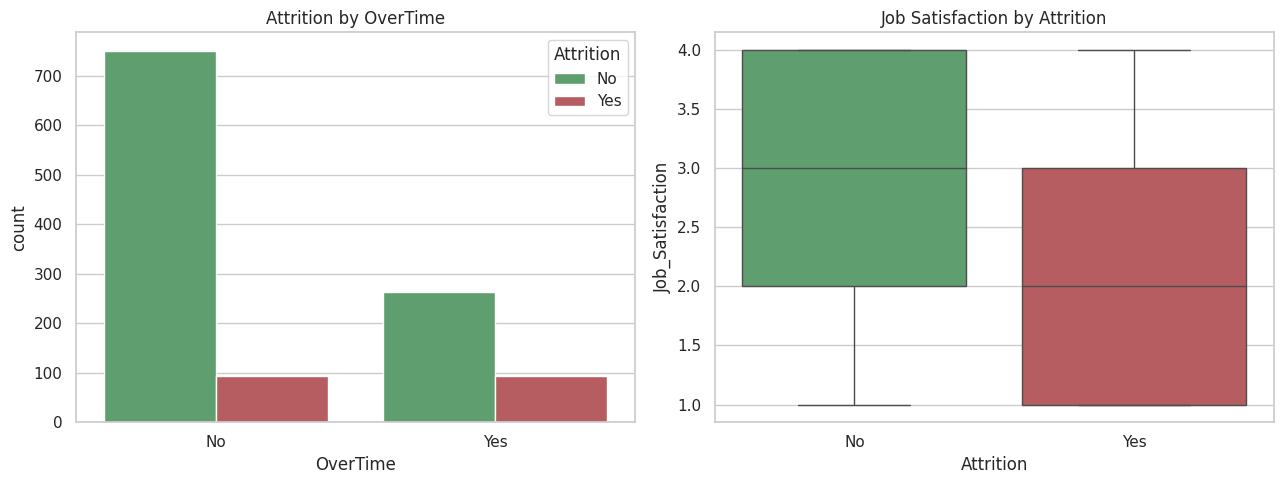

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.countplot(data=df, x="OverTime", hue="Attrition", ax=axes[0], palette=["#55A868", "#C44E52"])
axes[0].set_title("Attrition by OverTime")

sns.boxplot(data=df, x="Attrition", y="Job_Satisfaction", ax=axes[1], palette=["#55A868", "#C44E52"])
axes[1].set_title("Job Satisfaction by Attrition")
plt.tight_layout()
plt.savefig("charts/eda_overtime_satisfaction.png", dpi=120)
plt.show()

## 3. Preprocessing

In [5]:
model_df = df.copy()
model_df["Attrition_Flag"] = (model_df.Attrition == "Yes").astype(int)
model_df["OverTime_Flag"] = (model_df.OverTime == "Yes").astype(int)
model_df = pd.get_dummies(model_df, columns=["Department"], drop_first=True)

feature_cols = [c for c in model_df.columns if c not in
                ["Employee_ID", "Attrition", "OverTime", "Attrition_Flag"]]

X = model_df[feature_cols]
y = model_df["Attrition_Flag"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)

Train shape: (900, 11) | Test shape: (300, 11)


## 4. Logistic Regression Model

In [6]:
model = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_proba = model.predict_proba(X_test_scaled)[:, 1]

## 5. Evaluation

In [7]:
print("Accuracy: ", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:   ", round(recall_score(y_test, y_pred), 3))
print("F1 Score: ", round(f1_score(y_test, y_pred), 3))
print("ROC-AUC:  ", round(roc_auc_score(y_test, y_proba), 3))
print("\n", classification_report(y_test, y_pred, target_names=["Stayed", "Left"]))

Accuracy:  0.747
Precision: 0.356
Recall:    0.766
F1 Score:  0.486
ROC-AUC:   0.805

               precision    recall  f1-score   support

      Stayed       0.94      0.74      0.83       253
        Left       0.36      0.77      0.49        47

    accuracy                           0.75       300
   macro avg       0.65      0.75      0.66       300
weighted avg       0.85      0.75      0.78       300



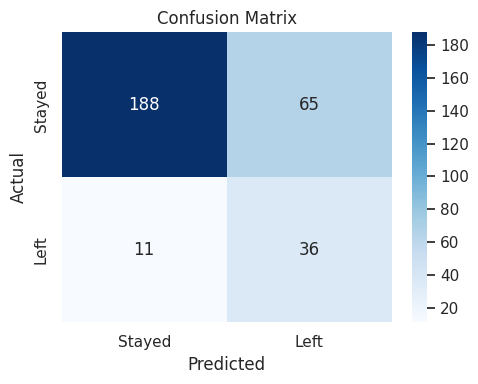

In [8]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Stayed", "Left"], yticklabels=["Stayed", "Left"], ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Confusion Matrix")
plt.tight_layout()
plt.savefig("charts/confusion_matrix.png", dpi=120)
plt.show()

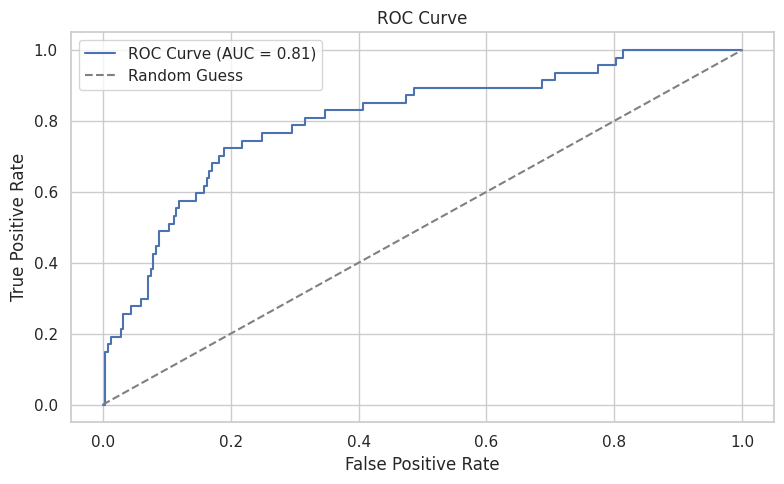

In [9]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
fig, ax = plt.subplots()
ax.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc_score(y_test, y_proba):.2f})", color="#4C72B0")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Guess")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve")
ax.legend()
plt.tight_layout()
plt.savefig("charts/roc_curve.png", dpi=120)
plt.show()

## 6. Feature Importance

/tmp/ipykernel_225/2754653112.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_df, x="Coefficient", y="Feature", ax=ax, palette="coolwarm")


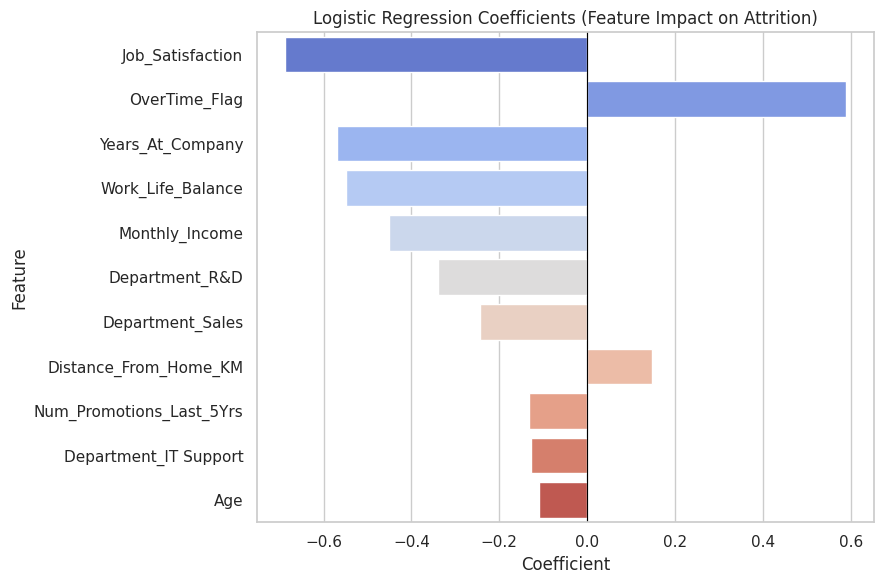

,Feature,Coefficient
3,Job_Satisfaction,-0.688701
7,OverTime_Flag,0.589084
2,Years_At_Company,-0.569794
4,Work_Life_Balance,-0.549830
1,Monthly_Income,-0.451398
9,Department_R&D,-0.340211
10,Department_Sales,-0.244209
5,Distance_From_Home_KM,0.148430
6,Num_Promotions_Last_5Yrs,-0.132451
8,Department_IT Support,-0.128519


In [10]:
coef_df = pd.DataFrame({
    "Feature": feature_cols,
    "Coefficient": model.coef_[0]
}).sort_values("Coefficient", key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=coef_df, x="Coefficient", y="Feature", ax=ax, palette="coolwarm")
ax.set_title("Logistic Regression Coefficients (Feature Impact on Attrition)")
ax.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.savefig("charts/feature_importance.png", dpi=120)
plt.show()

coef_df

## 7. Key Findings

- **OverTime is the strongest positive driver of attrition** — employees
  working overtime are substantially more likely to leave, even after
  controlling for other factors.
- **Job satisfaction and work-life balance are the strongest protective
  factors** — higher scores on both sharply reduce predicted attrition risk.
- **Distance from home has a smaller but positive effect** — longer commutes
  slightly increase attrition risk.
- **More promotions and longer tenure reduce attrition risk**, as expected.
- The model reaches a reasonable ROC-AUC on held-out test data, meaning it
  ranks at-risk employees well above chance — useful as an early-warning
  signal, not a certainty, for HR to prioritize retention conversations.

*(Findings are illustrative, generated from a synthetic dataset built with
intentional feature effects — the same classification workflow applies
directly to a real HR export.)*
